# India AQI Analysis: EDA and Forecasting
**Goal:** understand India's air-quality patterns from 425K+ daily readings, then forecast Delhi's seasonal AQI.

**Data:** `day_wise_aqi_data.csv` (one row per city per day). Keep this notebook in the same folder as the CSV.

**Sections:** 1) Load and quality checks, 2) EDA, 3) Like-for-like trend, 4) Forecasting, 5) Conclusions

In [1]:
import warnings, itertools
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX

plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.grid": True, "grid.alpha": 0.25})

## 1. Load and data-quality checks

In [2]:
df = pd.read_csv("day_wise_aqi_data.csv", parse_dates=["date"])
print("Shape:", df.shape)
print("Date range:", df["date"].min().date(), "to", df["date"].max().date())
print("States:", df["state"].nunique(), "| Areas:", df["area"].nunique())
df.head()

Shape: (425279, 7)
Date range: 2015-05-01 to 2025-06-19
States: 32 | Areas: 295


,date,state,area,number_of_monitoring_stations,prominent_pollutants,aqi_value,air_quality_status
0,2025-06-15,Rajasthan,Alwar,1.0,PM10,89,Satisfactory
1,2025-06-11,Rajasthan,Alwar,1.0,PM10,81,Satisfactory
2,2025-06-08,Rajasthan,Alwar,1.0,PM10,92,Satisfactory
3,2025-06-07,Rajasthan,Alwar,1.0,PM10,82,Satisfactory
4,2025-06-06,Rajasthan,Alwar,1.0,PM10,65,Satisfactory


In [3]:
print("Missing values per column:")
print(df.isna().sum())
# NB: two different cities are named "Aurangabad" (Bihar, Maharashtra), so check state + area + date
print("\nDuplicate city-day rows:", df.duplicated(subset=["state", "area", "date"]).sum())
print("AQI outside 0-500:", ((df["aqi_value"] < 0) | (df["aqi_value"] > 500)).sum())
df["aqi_value"].describe().round(1)

Missing values per column:
date                               0
state                              0
area                               0
number_of_monitoring_stations    141
prominent_pollutants               0
aqi_value                          0
air_quality_status                 0
dtype: int64

Duplicate city-day rows: 0
AQI outside 0-500: 0


count    425279.0
mean        118.7
std          79.5
min           3.0
25%          61.0
50%          96.0
75%         152.0
max         500.0
Name: aqi_value, dtype: float64

## 2. Exploratory analysis

In [4]:
df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month

# AQI health categories (same bands used in the Power BI dashboard)
bins = [-1, 50, 100, 150, 200, 300, 500]
labels = ["Good", "Moderate", "Poor", "Unhealthy", "Very Unhealthy", "Hazardous"]
df["aqi_category"] = pd.cut(df["aqi_value"], bins=bins, labels=labels)
print("Overall average AQI:", round(df["aqi_value"].mean(), 1))

Overall average AQI: 118.7


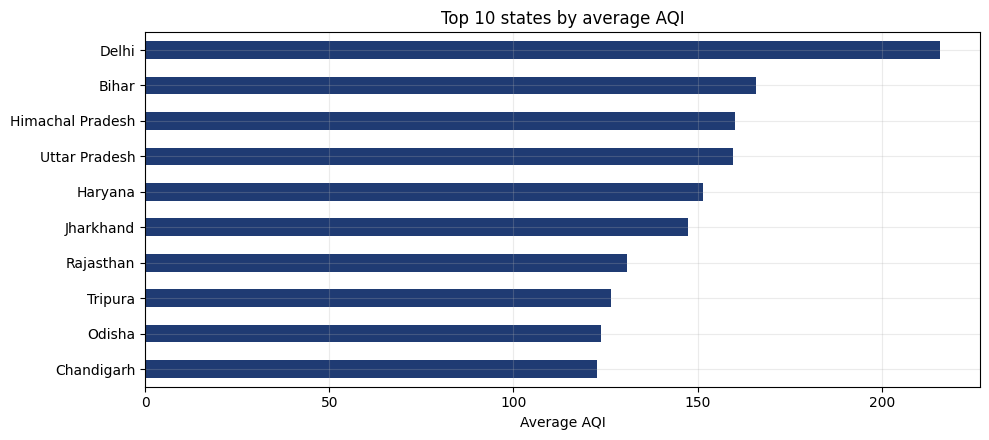

In [5]:
# Most polluted states
state_avg = df.groupby("state")["aqi_value"].mean().sort_values(ascending=False).head(10)
state_avg.sort_values().plot(kind="barh", color="#1f3b73")
plt.title("Top 10 states by average AQI"); plt.xlabel("Average AQI"); plt.ylabel("")
plt.tight_layout(); plt.show()

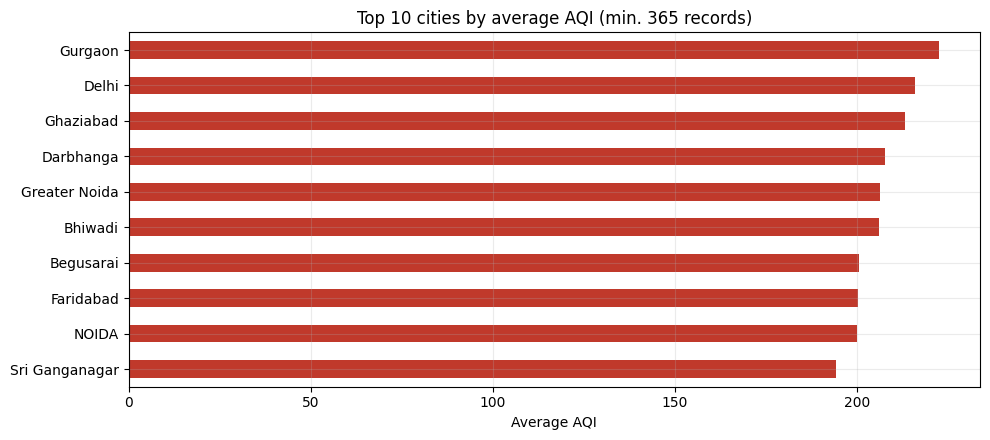

In [6]:
# Most polluted cities (at least 1 year of data)
g = df.groupby(["state", "area"])["aqi_value"].agg(["mean", "count"])
city_avg = g[g["count"] >= 365]["mean"].sort_values(ascending=False).head(10)
city_avg.droplevel(0).sort_values().plot(kind="barh", color="#c0392b")
plt.title("Top 10 cities by average AQI (min. 365 records)"); plt.xlabel("Average AQI"); plt.ylabel("")
plt.tight_layout(); plt.show()

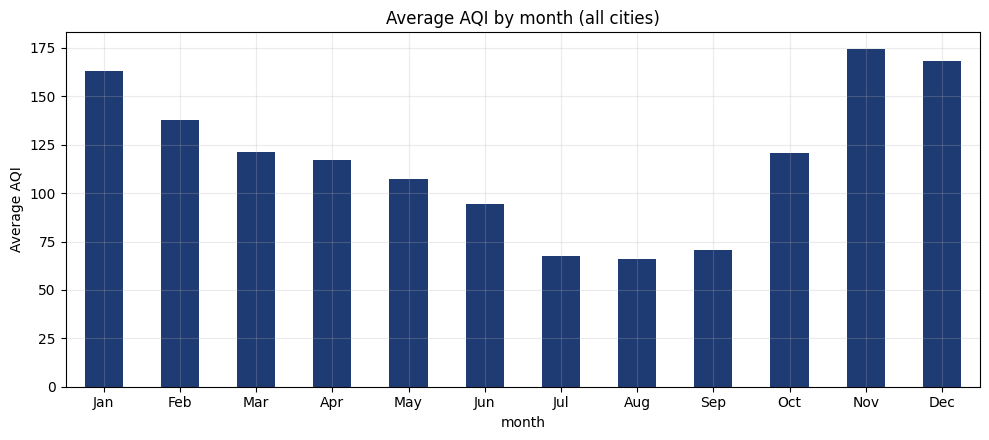

Highest month: 11 (174) | Lowest month: 8 (66)


In [7]:
# Seasonality
monthly_avg = df.groupby("month")["aqi_value"].mean()
monthly_avg.plot(kind="bar", color="#1f3b73")
plt.xticks(range(12), ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"], rotation=0)
plt.title("Average AQI by month (all cities)"); plt.ylabel("Average AQI")
plt.tight_layout(); plt.show()
print(f"Highest month: {monthly_avg.idxmax()} ({monthly_avg.max():.0f}) | Lowest month: {monthly_avg.idxmin()} ({monthly_avg.min():.0f})")

Share of readings by AQI category (%)
aqi_category
Good              16.4
Moderate          36.5
Poor              21.5
Unhealthy         11.0
Very Unhealthy    10.3
Hazardous          4.2
Name: proportion, dtype: float64 



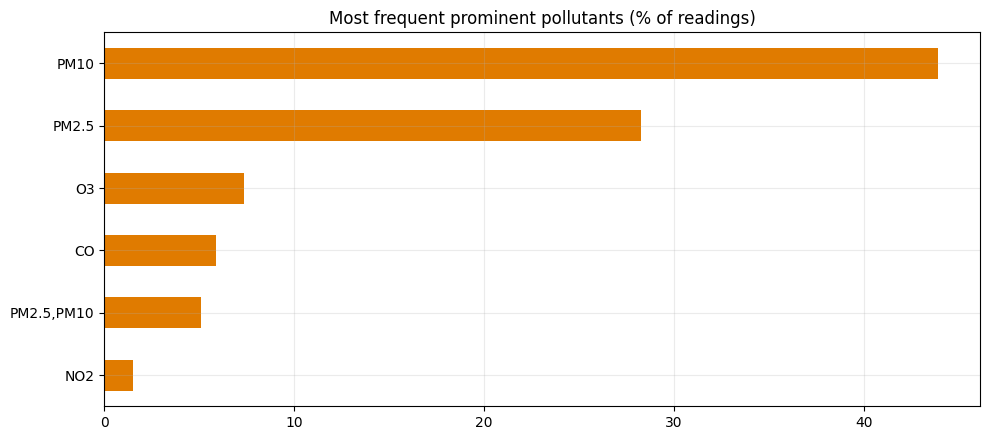

Average AQI by pollutant:
prominent_pollutants
PM2.5            177.6
PM2.5,PM10       142.4
O3,PM2.5,PM10    118.2
PM2.5,NO2        115.2
PM2.5,O3         113.7
Name: aqi_value, dtype: float64


In [8]:
# Category share and pollutants
share = (df["aqi_category"].value_counts(normalize=True).reindex(labels) * 100).round(1)
print("Share of readings by AQI category (%)"); print(share, "\n")

poll = df["prominent_pollutants"].value_counts(normalize=True).head(6) * 100
poll.sort_values().plot(kind="barh", color="#e07b00")
plt.title("Most frequent prominent pollutants (% of readings)"); plt.ylabel("")
plt.tight_layout(); plt.show()
print("Average AQI by pollutant:"); print(df.groupby("prominent_pollutants")["aqi_value"].mean().round(1).sort_values(ascending=False).head(5))

## 3. Like-for-like trend
Monitoring coverage expanded sharply over the years, so comparing raw yearly averages is misleading. Here we compare only cities that reported data in every year from 2019 to 2024.

In [9]:
cov = df.groupby("year").agg(cities=("area", "nunique"), records=("aqi_value", "size"))
cov

,cities,records
year,,
2015,22,2910
2016,33,7501
2017,54,12213
2018,76,21481
2019,115,33670
2020,135,40179
2021,169,47642
2022,207,57154
2023,269,76978


Cities with data in every year 2019-2024:

 112


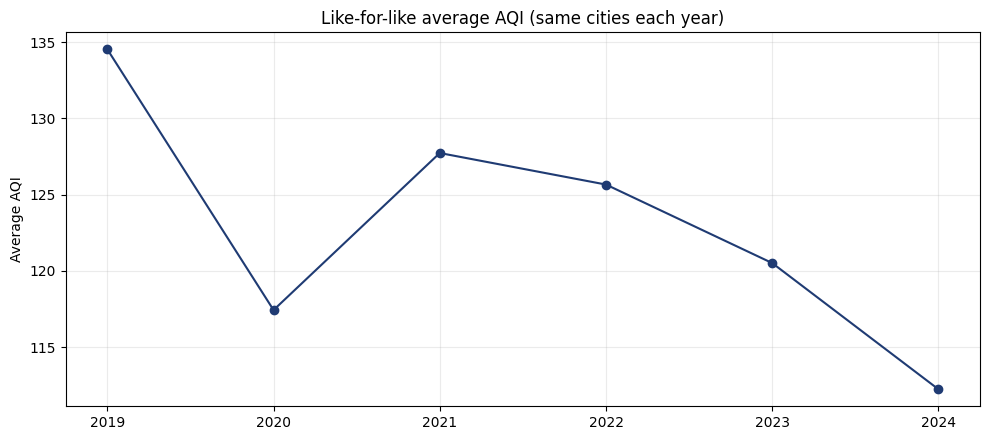

year
2019    134.5
2020    117.4
2021    127.7
2022    125.7
2023    120.5
2024    112.2
dtype: float64


In [10]:
yearly = (df[df["year"].between(2019, 2024)].groupby(["state", "area", "year"])["aqi_value"].mean().unstack())
consistent = yearly.dropna()          # cities present in all 6 years
print("Cities with data in every year 2019-2024:", len(consistent))

trend = consistent.mean()
trend.plot(marker="o", color="#1f3b73")
plt.title("Like-for-like average AQI (same cities each year)"); plt.ylabel("Average AQI"); plt.xlabel("")
plt.tight_layout(); plt.show()
print(trend.round(1))

## 4. Forecasting Delhi's monthly AQI
Delhi has complete daily data from May 2015 to June 2025, so its series is not affected by network expansion.
**Plan:** monthly averages, hold out the last 24 months, compare a seasonal-naive baseline against SARIMA, then forecast 12 months ahead.

121 months: May 2015 to May 2025


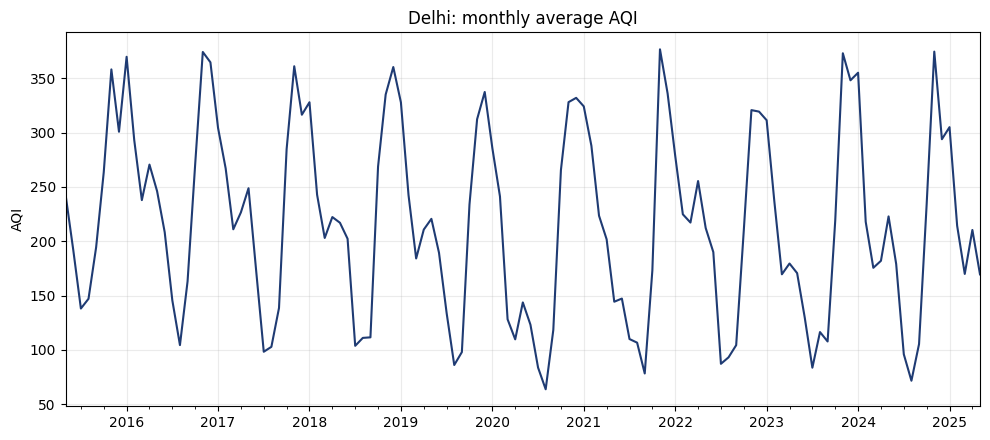

In [11]:
CITY, TEST_MONTHS, HORIZON = "Delhi", 24, 12

daily = df[df["area"] == CITY].set_index("date")["aqi_value"].sort_index()
y = daily.resample("MS").mean()

# keep complete months only
if daily.index.max().day < daily.index.max().days_in_month:
    y = y[:-1]
if daily.index.min().day != 1:
    y = y[1:]

print(f"{len(y)} months: {y.index.min():%b %Y} to {y.index.max():%b %Y}")
y.plot(color="#1f3b73"); plt.title(f"{CITY}: monthly average AQI"); plt.ylabel("AQI"); plt.xlabel("")
plt.tight_layout(); plt.show()

In [12]:
train, test = y[:-TEST_MONTHS], y[-TEST_MONTHS:]

def metrics(actual, pred):
    err = actual - pred
    return {"MAE": round(float(np.abs(err).mean()), 1),
            "RMSE": round(float(np.sqrt((err ** 2).mean())), 1),
            "MAPE_%": round(float((np.abs(err) / actual).mean() * 100), 1)}

# Baseline: same month last year
naive = pd.Series(np.resize(train.values[-12:], len(test)), index=test.index)
naive_m = metrics(test, naive)
naive_m

{'MAE': 21.3, 'RMSE': 28.3, 'MAPE_%': 10.7}

In [13]:
# SARIMA on log-AQI, order picked by AIC
log_train = np.log(train)
best = None
for p, d, q, P, Q in itertools.product([0, 1, 2], [0, 1], [0, 1, 2], [0, 1], [0, 1]):
    try:
        res = SARIMAX(log_train, order=(p, d, q), seasonal_order=(P, 1, Q, 12)).fit(disp=False)
        if best is None or res.aic < best[0]:
            best = (res.aic, (p, d, q), (P, 1, Q, 12))
    except Exception:
        continue
_, order, seasonal = best
print("Selected model: SARIMA", order, seasonal)

fit = SARIMAX(log_train, order=order, seasonal_order=seasonal).fit(disp=False)
sarima = pd.Series(np.exp(fit.get_forecast(len(test)).predicted_mean.values), index=test.index)
sarima_m = metrics(test, sarima)

pd.DataFrame({"Seasonal naive": naive_m, "SARIMA": sarima_m}).T

Selected model: SARIMA (1, 0, 0) (0, 1, 1, 12)


,MAE,RMSE,MAPE_%
Seasonal naive,21.3,28.3,10.7
SARIMA,19.7,23.6,10.4


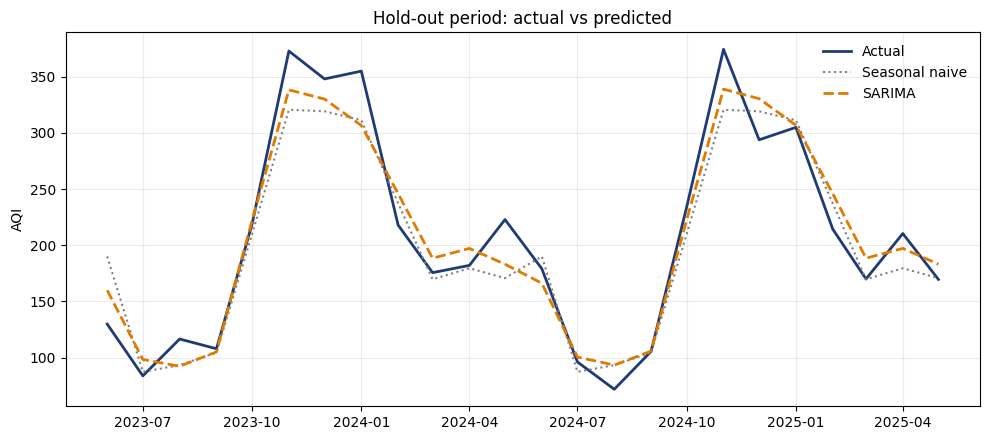

In [14]:
plt.plot(test.index, test.values, label="Actual", color="#1f3b73", lw=2)
plt.plot(test.index, naive.values, label="Seasonal naive", color="grey", ls=":")
plt.plot(test.index, sarima.values, label="SARIMA", color="#e07b00", ls="--", lw=2)
plt.title("Hold-out period: actual vs predicted"); plt.ylabel("AQI"); plt.legend(frameon=False)
plt.tight_layout(); plt.show()

In [15]:
# Refit on all data and forecast the next 12 months
final = SARIMAX(np.log(y), order=order, seasonal_order=seasonal).fit(disp=False)
fc = final.get_forecast(HORIZON)
ci = fc.conf_int(alpha=0.05)
future = pd.date_range(y.index.max() + pd.offsets.MonthBegin(1), periods=HORIZON, freq="MS")

forecast = pd.DataFrame({
    "city": CITY,
    "month": future,
    "forecast_aqi": np.exp(fc.predicted_mean.values).round(1),
    "lower_95": np.exp(ci.iloc[:, 0].values).round(1),
    "upper_95": np.minimum(np.exp(ci.iloc[:, 1].values), 500).round(1),   # AQI caps at 500
})
forecast.to_csv("forecast_delhi.csv", index=False)
forecast

,city,month,forecast_aqi,lower_95,upper_95
0,Delhi,2025-06-01,152.2,110.8,209.1
1,Delhi,2025-07-01,93.8,65.6,134.0
2,Delhi,2025-08-01,90.0,62.4,129.8
3,Delhi,2025-09-01,106.7,73.8,154.4
4,Delhi,2025-10-01,226.4,156.4,327.6
5,Delhi,2025-11-01,354.3,244.8,500.0
6,Delhi,2025-12-01,323.7,223.6,468.6
7,Delhi,2026-01-01,315.8,218.2,457.2
8,Delhi,2026-02-01,232.5,160.6,336.6
9,Delhi,2026-03-01,181.5,125.4,262.7


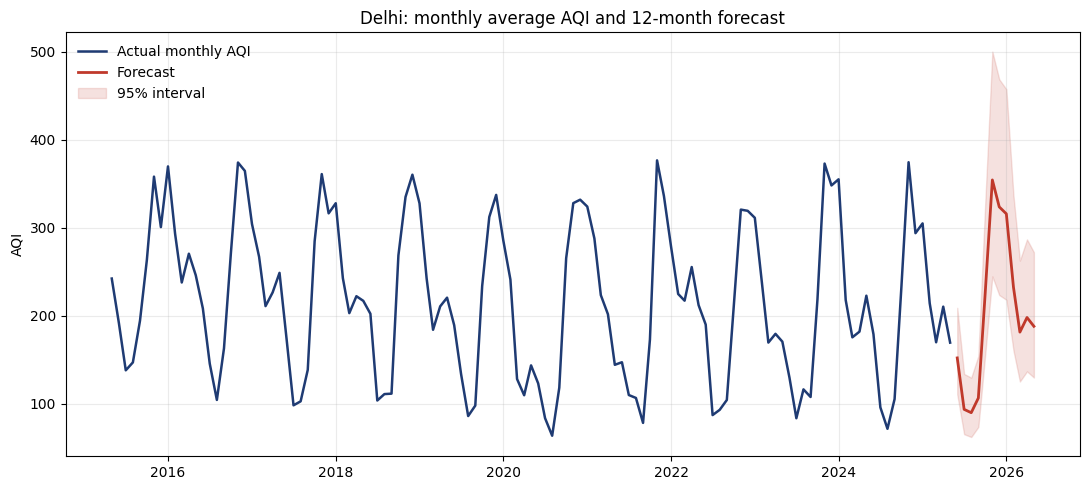

In [16]:
fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(y.index, y.values, color="#1f3b73", lw=1.8, label="Actual monthly AQI")
ax.plot(forecast["month"], forecast["forecast_aqi"], color="#c0392b", lw=2, label="Forecast")
ax.fill_between(forecast["month"], forecast["lower_95"], forecast["upper_95"], color="#c0392b", alpha=0.15, label="95% interval")
ax.set_title(f"{CITY}: monthly average AQI and {HORIZON}-month forecast"); ax.set_ylabel("AQI"); ax.legend(frameon=False)
plt.tight_layout(); fig.savefig("forecast_delhi.png", dpi=160); plt.show()

## 5. Conclusions
- **Hotspots:** Delhi-NCR cities (Gurgaon, Delhi, Ghaziabad) have the highest average AQI; the north-east (e.g. Mizoram) is the cleanest.
- **Seasonality:** AQI peaks in November to January and is lowest in the monsoon months.
- **Pollutants:** PM10 and PM2.5 dominate; PM2.5-driven days have the highest average AQI.
- **Trend:** on a like-for-like basis (same cities every year) average AQI fell between 2019 and 2024. This analysis does not show why.
- **Forecast:** SARIMA beats the seasonal-naive baseline only modestly, because most of Delhi's AQI is a stable annual cycle. The forecast shows the seasonal pattern; it does not model weather or policy effects.
- **Limitations:** the data is univariate and covers one city for forecasting; coverage differs by state and year; 2025 is a partial year.